In [2]:
from dotenv import load_dotenv
load_dotenv()

import os
import sys
sys.path.append("../streamlit_app")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sqlalchemy import create_engine

plt.rcParams["figure.figsize"] = (10, 5)

engine = create_engine(os.environ["DATABASE_URL"].replace("postgres://", "postgresql://", 1))
df_km = pd.read_sql("SELECT * FROM activities_km", engine)
df_act = pd.read_sql("SELECT * FROM activities_enriched", engine)

print(f"df_km  : {len(df_km)} lignes ({df_km['activity_id'].nunique()} sorties)")
print(f"df_act : {len(df_act)} sorties, {len(df_act.columns)} colonnes")

df_km  : 783 lignes (131 sorties)
df_act : 131 sorties, 45 colonnes


Merger et préparer

In [5]:
# Joindre les features sortie à chaque ligne km (pas de suffixes nécessaires, aucun nom en commun)
act_features = ["id", "distance_km", "weather_temperature", "weather_humidity",
                "elev_per_km", "pace_last_5_mean", "vol_7d_km", "vol_28d_km",
                "pace_min_km", "start_date_local"]
df = df_km.merge(df_act[act_features], left_on="activity_id", right_on="id")

# Renommer pour clarté
df = df.rename(columns={
    "pace_min_per_km": "pace_km",      # pace du km courant (y du modèle)
    "pace_min_km": "pace_sortie",      # pace moyenne de la sortie
    "km_distance_m": "km_dist_m",      # m du km courant
    "distance_km": "dist_totale_km",   # distance totale de la sortie
})

print("Colonnes utiles :")
print(df[["activity_id", "km_index", "pace_km", "fraction_completed",
          "avg_grade_pct", "avg_heartrate",
          "dist_totale_km", "weather_temperature", "elev_per_km",
          "pace_last_5_mean"]].head())

print(f"\nTotal : {len(df)} lignes km")

Colonnes utiles :
   activity_id  km_index   pace_km  fraction_completed  avg_grade_pct  \
0  11346532154         1  4.611529            0.333333       0.861244   
1  11346532154         2  4.293208            0.666667      -0.257684   
2  11346532154         3  4.161538            1.000000      -0.957047   
3  11351598892         1  4.427736            0.250000      -0.863705   
4  11351598892         2  4.467423            0.500000       0.271331   

   avg_heartrate  dist_totale_km  weather_temperature  elev_per_km  \
0            NaN          2.5716                 16.4     3.499767   
1            NaN          2.5716                 16.4     3.499767   
2            NaN          2.5716                 16.4     3.499767   
3            NaN          3.3113                 16.9     6.039924   
4            NaN          3.3113                 16.9     6.039924   

   pace_last_5_mean  
0               NaN  
1               NaN  
2               NaN  
3           4.34254  
4           

Filtres et échantillon de modélisation

In [6]:
# Mêmes filtres de cohérence qu'en par-sortie + exclusion km partiels
mask = (
    (~df["is_partial"])                           # km complet uniquement
    & (df["pace_km"].between(3, 10))              # paces plausibles
    & (df["dist_totale_km"] >= 1)                 # sorties >= 1 km
    & (df["dist_totale_km"] < 30)                 # exclut long trail
    & (df["pace_last_5_mean"].notna())            # feature forme dispo
)
dfm = df[mask].copy()

# On garde les sorties avec >= 3 km exploitables
counts = dfm.groupby("activity_id")["km_index"].transform("count")
dfm = dfm[counts >= 3]

print(f"n lignes km après filtres : {len(dfm)}")
print(f"n sorties               : {dfm['activity_id'].nunique()}")
print(f"\nStats pace par km : {dfm['pace_km'].describe().round(3)}")
print(f"\nStats pace moyennes par sortie : {dfm.groupby('activity_id')['pace_km'].mean().describe().round(3)}")

n lignes km après filtres : 570
n sorties               : 88

Stats pace par km : count    570.000
mean       5.048
std        0.635
min        3.576
25%        4.581
50%        5.012
75%        5.445
max        6.978
Name: pace_km, dtype: float64

Stats pace moyennes par sortie : count    88.000
mean      4.941
std       0.570
min       3.857
25%       4.512
50%       4.880
75%       5.280
max       6.679
Name: pace_km, dtype: float64


Modèle NULL : décomposition variance de base

In [7]:
# Modèle null = juste effet aléatoire sortie, pas de prédicteur
# pace_km ~ 1 + (1 | activity_id)
null_model = smf.mixedlm("pace_km ~ 1", data=dfm, groups=dfm["activity_id"]).fit(method="lbfgs")
print(null_model.summary())

# ICC = variance entre-sorties / (variance entre + variance intra)
var_between = null_model.cov_re.iloc[0, 0]
var_within = null_model.scale
icc = var_between / (var_between + var_within)

print(f"\n=== Décomposition variance (modèle null) ===")
print(f"Variance entre sorties (between) : {var_between:.4f} min²/km²  →  σ = {np.sqrt(var_between)*60:.1f} s/km")
print(f"Variance intra-sortie (within)   : {var_within:.4f} min²/km²  →  σ = {np.sqrt(var_within)*60:.1f} s/km")
print(f"ICC = {icc:.3f}")
print(f"\n→ {icc*100:.1f} % de la variance de la pace instantanée vient de la 'forme/contexte de la sortie'")
print(f"→ {(1-icc)*100:.1f} % vient de la variation intra-sortie (fatigue, pacing, dynamique)")

         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: pace_km  
No. Observations: 570     Method:             REML     
No. Groups:       88      Scale:              0.1225   
Min. group size:  3       Log-Likelihood:     -331.0349
Max. group size:  25      Converged:          Yes      
Mean group size:  6.5                                  
-------------------------------------------------------
              Coef. Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept     4.946    0.061 81.661 0.000  4.827  5.064
Group Var     0.299    0.152                           


=== Décomposition variance (modèle null) ===
Variance entre sorties (between) : 0.2992 min²/km²  →  σ = 32.8 s/km
Variance intra-sortie (within)   : 0.1225 min²/km²  →  σ = 21.0 s/km
ICC = 0.709

→ 70.9 % de la variance de la pace instantanée vient de la 'forme/contexte de la sortie'
→ 29.1 % vient de la variation intra-sortie (fatig

Modèle complet avec features

In [8]:
# Modèle complet : contexte sortie + état d'avancement + forme
# pace_km ~ T° + T² + dist_totale + elev_per_km + pace_last_5 + fraction_completed + avg_grade_pct + (1 | activity_id)
FORMULA_MIXED = (
    "pace_km ~ weather_temperature + I(weather_temperature**2) "
    "+ dist_totale_km + elev_per_km + pace_last_5_mean "
    "+ fraction_completed + avg_grade_pct"
)

full_model = smf.mixedlm(FORMULA_MIXED, data=dfm, groups=dfm["activity_id"]).fit(method="lbfgs")
print(full_model.summary())

# Nouvelle décomposition après contrôle
var_between_full = full_model.cov_re.iloc[0, 0]
var_within_full = full_model.scale
icc_full = var_between_full / (var_between_full + var_within_full)

print(f"\n=== Décomposition variance (modèle complet) ===")
print(f"Variance between résiduelle : {var_between_full:.4f}  →  σ = {np.sqrt(var_between_full)*60:.1f} s/km")
print(f"Variance within résiduelle  : {var_within_full:.4f}  →  σ = {np.sqrt(var_within_full)*60:.1f} s/km")
print(f"ICC résiduel = {icc_full:.3f}")

# Part expliquée par les features vs modèle null
r2_between = 1 - var_between_full / var_between
r2_within = 1 - var_within_full / var_within
print(f"\n→ Les features expliquent {r2_between*100:.1f} % de la variance BETWEEN (jour vs jour)")
print(f"→ Les features expliquent {r2_within*100:.1f} % de la variance WITHIN (intra-sortie)")

                Mixed Linear Model Regression Results
Model:                 MixedLM      Dependent Variable:      pace_km  
No. Observations:      570          Method:                  REML     
No. Groups:            88           Scale:                   0.1002   
Min. group size:       3            Log-Likelihood:          -287.6583
Max. group size:       25           Converged:               Yes      
Mean group size:       6.5                                            
----------------------------------------------------------------------
                            Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------------
Intercept                    3.656    0.804  4.549 0.000  2.081  5.232
weather_temperature         -0.103    0.035 -2.897 0.004 -0.172 -0.033
I(weather_temperature ** 2)  0.003    0.001  2.752 0.006  0.001  0.005
dist_totale_km               0.054    0.014  3.978 0.000  0.028  0.081
elev_per_km            

Interprétation chiffrée

In [9]:
# Décomposition finale en 4 blocs pour la soutenance
total_var = var_between + var_within
feat_between = var_between - var_between_full
feat_within = var_within - var_within_full

print(f"=== DÉCOMPOSITION FINALE DE LA VARIANCE pace instantanée ===")
print(f"Total variance initiale : {total_var:.4f}  (σ = {np.sqrt(total_var)*60:.1f} s/km)\n")
print(f"{'Composante':<45} {'Variance':>10} {'% du total':>12}")
print("-" * 72)
print(f"{'Expliqué par features (effet fixe)':<45} {feat_between + feat_within:>10.4f} {(feat_between + feat_within)/total_var*100:>11.1f} %")
print(f"  dont au niveau sortie (jour vs jour)       {feat_between:>10.4f} {feat_between/total_var*100:>11.1f} %")
print(f"  dont au niveau intra-sortie (avancement)   {feat_within:>10.4f} {feat_within/total_var*100:>11.1f} %")
print(f"{'Forme du jour résiduelle (effet aléatoire)':<45} {var_between_full:>10.4f} {var_between_full/total_var*100:>11.1f} %")
print(f"{'Bruit intra-sortie résiduel':<45} {var_within_full:>10.4f} {var_within_full/total_var*100:>11.1f} %")

=== DÉCOMPOSITION FINALE DE LA VARIANCE pace instantanée ===
Total variance initiale : 0.4218  (σ = 39.0 s/km)

Composante                                      Variance   % du total
------------------------------------------------------------------------
Expliqué par features (effet fixe)                0.1095        26.0 %
  dont au niveau sortie (jour vs jour)           0.0871        20.7 %
  dont au niveau intra-sortie (avancement)       0.0223         5.3 %
Forme du jour résiduelle (effet aléatoire)        0.2121        50.3 %
Bruit intra-sortie résiduel                       0.1002        23.8 %


Figure de décomposition de variance (barres empilées)

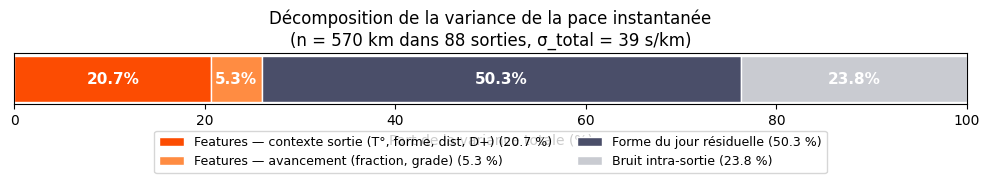

In [10]:
fig, ax = plt.subplots(figsize=(10, 2.5))

parts = {
    "Features — contexte sortie (T°, forme, dist, D+)": (feat_between/total_var*100, "#FC4C02"),
    "Features — avancement (fraction, grade)":          (feat_within/total_var*100,  "#FF8C42"),
    "Forme du jour résiduelle":                         (var_between_full/total_var*100, "#4A4E69"),
    "Bruit intra-sortie":                               (var_within_full/total_var*100,  "#C9CBD1"),
}

left = 0
for label, (pct, color) in parts.items():
    ax.barh(0, pct, left=left, color=color, edgecolor="white", label=f"{label} ({pct:.1f} %)")
    if pct > 4:
        ax.text(left + pct/2, 0, f"{pct:.1f}%", ha="center", va="center",
                color="white", fontweight="bold", fontsize=11)
    left += pct

ax.set_xlim(0, 100)
ax.set_yticks([])
ax.set_xlabel("Part de la variance totale (%)")
ax.set_title(f"Décomposition de la variance de la pace instantanée\n"
             f"(n = 570 km dans 88 sorties, σ_total = 39 s/km)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.4), ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig("../docs/figures/09_variance_decomp.png", dpi=150, bbox_inches="tight")
plt.show()

Figure effet fraction_completed (negative split)

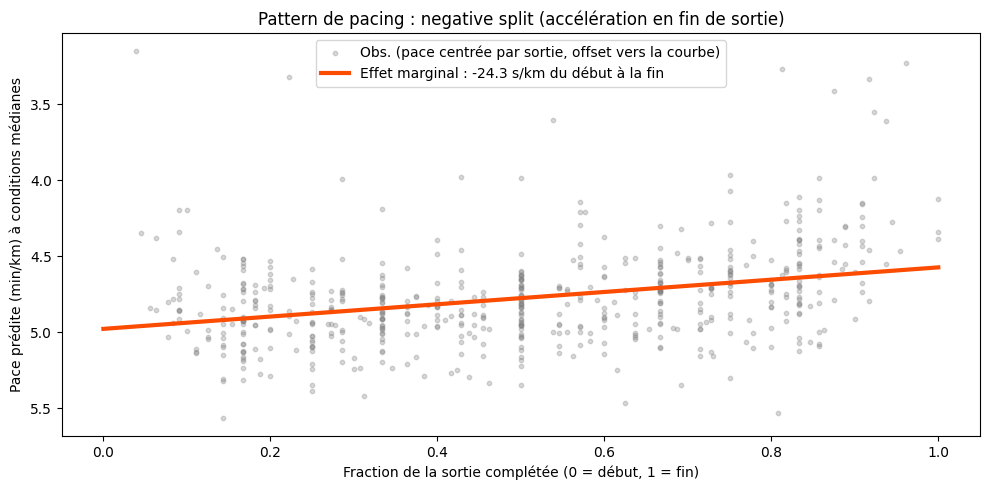


→ Entre début et fin de sortie, tu accélères en moyenne de 24.3 s/km
→ p = 3.91e-14 (hautement significatif)


In [11]:
# Grille fraction + prédictions
frac_grid = np.linspace(0, 1, 50)
med_T = dfm["weather_temperature"].median()
med_dist = dfm["dist_totale_km"].median()
med_elev = dfm["elev_per_km"].median()
med_pace5 = dfm["pace_last_5_mean"].median()
med_grade = dfm["avg_grade_pct"].median()

p = full_model.fe_params
pred = (p["Intercept"]
        + p["weather_temperature"] * med_T
        + p["I(weather_temperature ** 2)"] * med_T**2
        + p["dist_totale_km"] * med_dist
        + p["elev_per_km"] * med_elev
        + p["pace_last_5_mean"] * med_pace5
        + p["fraction_completed"] * frac_grid
        + p["avg_grade_pct"] * med_grade)

fig, ax = plt.subplots(figsize=(10, 5))

# Nuage des observations centrées par sortie (pour voir l'effet net)
dfm_centered = dfm.copy()
dfm_centered["pace_centered"] = dfm_centered.groupby("activity_id")["pace_km"].transform(lambda x: x - x.mean())
ax.scatter(dfm_centered["fraction_completed"], dfm_centered["pace_centered"] + pred.mean(),
           alpha=0.3, s=10, color="gray", label="Obs. (pace centrée par sortie, offset vers la courbe)")

# Courbe prédite (effet marginal)
ax.plot(frac_grid, pred, color="#FC4C02", lw=3,
        label=f"Effet marginal : {p['fraction_completed']*60:.1f} s/km du début à la fin")

ax.set_xlabel("Fraction de la sortie complétée (0 = début, 1 = fin)")
ax.set_ylabel("Pace prédite (min/km) à conditions médianes")
ax.set_title("Pattern de pacing : negative split (accélération en fin de sortie)")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
plt.savefig("../docs/figures/09_negative_split.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\n→ Entre début et fin de sortie, tu accélères en moyenne de {-p['fraction_completed']*60:.1f} s/km")
print(f"→ p = {full_model.pvalues['fraction_completed']:.2e} (hautement significatif)")

Raffinement : virer elev_per_km et refit

In [12]:
FORMULA_V2 = (
    "pace_km ~ weather_temperature + I(weather_temperature**2) "
    "+ dist_totale_km + pace_last_5_mean "
    "+ fraction_completed + avg_grade_pct"
)
model_v2 = smf.mixedlm(FORMULA_V2, data=dfm, groups=dfm["activity_id"]).fit(method="lbfgs")
print(model_v2.summary())

# Vérif que décomposition reste stable
var_between_v2 = model_v2.cov_re.iloc[0, 0]
var_within_v2 = model_v2.scale
print(f"\nAvec elev_per_km : between={var_between_full:.4f}, within={var_within_full:.4f}")
print(f"Sans elev_per_km : between={var_between_v2:.4f}, within={var_within_v2:.4f}")

                Mixed Linear Model Regression Results
Model:                 MixedLM      Dependent Variable:      pace_km  
No. Observations:      570          Method:                  REML     
No. Groups:            88           Scale:                   0.1002   
Min. group size:       3            Log-Likelihood:          -284.7767
Max. group size:       25           Converged:               Yes      
Mean group size:       6.5                                            
----------------------------------------------------------------------
                            Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------------
Intercept                    3.764    0.800  4.705 0.000  2.196  5.331
weather_temperature         -0.103    0.035 -2.902 0.004 -0.172 -0.033
I(weather_temperature ** 2)  0.003    0.001  2.703 0.007  0.001  0.005
dist_totale_km               0.054    0.014  3.909 0.000  0.027  0.080
pace_last_5_mean       